# 03｜AI 基建：资本开支有没有挤压现金流

用 MSFT、AMZN、GOOGL、META 的官方 2024 年报列示的 2022—2024 财政年度做小型研究。**这是年度教学样本，不是最新季度投资结论。**

研究分两层：能验证的公司总量现金变化，以及仍不能从总量识别的 AI 投资回报。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/research-playbook.properties").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tools.research_playbook.data import load_frame, inventory, data_root, sha
from tools.research_playbook.analysis import plot_style
plot_style()
pd.set_option("display.max_columns", 12)

## 1. 先核对数字的“身份证”

每行保留公司、财政年、期末和原文来源。金额统一为百万美元。MSFT 的财政年截至 6 月，其余三家截至 12 月；同样写着 2024，也不是完全相同的经济时间窗。空白字段表示未录入，不能补零。

In [2]:
f=load_frame("ai_annual")
display(f[["symbol","fiscal_year","period_end","revenue_usd_m","cfo_usd_m","cash_ppe_usd_m"]])
source_notes=json.loads((ROOT/"research/data/ai-sources.json").read_text())
display(pd.DataFrame(source_notes["sources"]).T[["url","locator","capex_scope","da_scope"]])

,symbol,fiscal_year,period_end,revenue_usd_m,cfo_usd_m,cash_ppe_usd_m
0,AMZN,2022,2022-12-31,513983,46752,63645
1,AMZN,2023,2023-12-31,574785,84946,52729
2,AMZN,2024,2024-12-31,637959,115877,82999
3,GOOGL,2022,2022-12-31,282836,91495,31485
4,GOOGL,2023,2023-12-31,307394,101746,32251
5,GOOGL,2024,2024-12-31,350018,125299,52535
6,META,2022,2022-12-31,116609,50475,31186
7,META,2023,2023-12-31,134902,71113,27045
8,META,2024,2024-12-31,164501,91328,37256
9,MSFT,2022,2022-06-30,198270,89035,23886


,url,locator,capex_scope,da_scope
msft_ar24,https://www.microsoft.com/investor/reports/ar24/,Income Statements；Cash Flows Statements，2024/2...,现金购建固定资产，不含非现金融资租赁新增,折旧、摊销及其他；不能称为纯服务器折旧
amzn_10k24,https://www.sec.gov/Archives/edgar/data/101872...,Consolidated Statements of Cash Flows p36；Stat...,记录总现金购置及出售/激励收入；公司FCF采用净购置口径,含固定资产、资本化内容、经营租赁资产及其他，不能横比为纯折旧
goog_10k24,https://www.sec.gov/Archives/edgar/data/165204...,Consolidated Statements of Income；Consolidated...,现金购置固定资产，不含未付及非现金融资,固定资产折旧，不等同于其他公司的折旧摊销及其他合计
meta_10k24,https://www.sec.gov/Archives/edgar/data/132680...,Statements of Income p87；Statements of Cash Fl...,现金购置固定资产；公司FCF另扣融资租赁本金,折旧与摊销


## 2. 统一计算口径

`现金剩余 = 经营现金流 − 现金购置固定资产`。这是一项透明的分析指标，**不自动等于公司公布的 FCF**。资本开支强度是现金购置固定资产／收入；现金剩余率是现金剩余／收入。先看公司内部变化，再考虑跨公司比较。

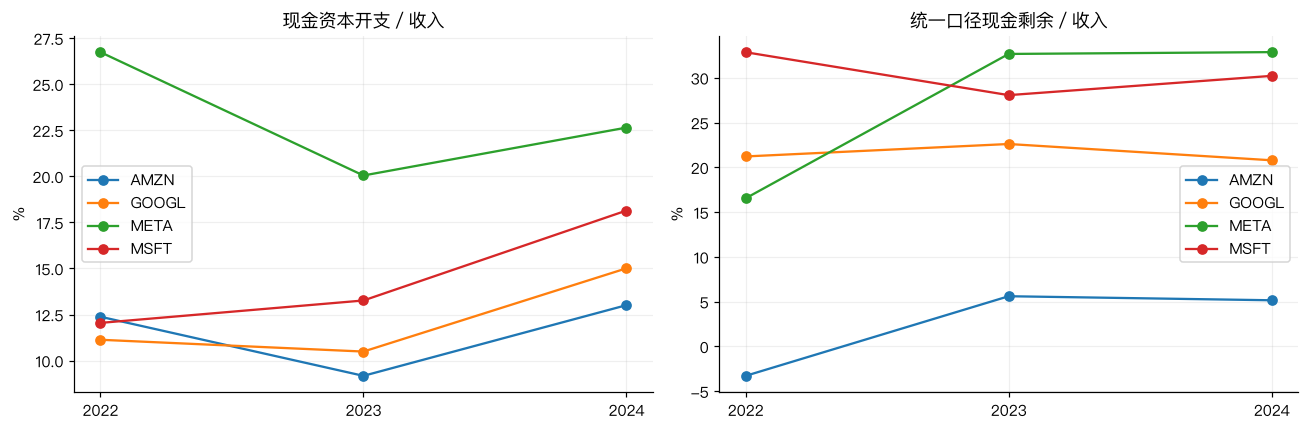

In [3]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
for symbol,g in f.groupby("symbol"):
    axs[0].plot(g.fiscal_year,g.cash_capex_to_revenue*100,marker="o",label=symbol)
    axs[1].plot(g.fiscal_year,g.cash_surplus_margin*100,marker="o",label=symbol)
axs[0].set_title("现金资本开支／收入"); axs[1].set_title("统一口径现金剩余／收入")
for ax in axs: ax.set_xticks([2022,2023,2024]); ax.set_ylabel("%"); ax.legend()
plt.tight_layout(); plt.show()

**读图：** 左边上升表示每单位收入对应的现金投入增加；右边下降表示扣除该投入后剩余现金占比下降。但经营现金流会受应收、应付和税款时点影响，不等于利润。两条线同步变化也不能证明“AI 导致”变化。

In [4]:
growth=f.sort_values(["symbol","fiscal_year"]).copy()
for col in ["revenue_usd_m","cfo_usd_m","cash_ppe_usd_m"]:
    growth[col+"_yoy"]=growth.groupby("symbol")[col].pct_change(fill_method=None)
display(growth[growth.fiscal_year==2024][["symbol","revenue_usd_m_yoy","cfo_usd_m_yoy","cash_ppe_usd_m_yoy","cash_surplus_usd_m"]])

,symbol,revenue_usd_m_yoy,cfo_usd_m_yoy,cash_ppe_usd_m_yoy,cash_surplus_usd_m
2,AMZN,0.109909,0.364125,0.574067,32878
5,GOOGL,0.138662,0.231488,0.628942,72764
8,META,0.219411,0.284266,0.377556,54072
11,MSFT,0.156700,0.353566,0.582417,74071


## 3. 两个容易误算的真实例子

Amazon 披露的 FCF 使用扣除出售和激励收入后的净购置额；Meta 披露的 FCF 还扣融资租赁本金。不能把两家的 FCF 差异全解释成经营能力。下面逐项搭桥，用代码核对原文已报告的数值。

,AMZN,META
经营现金流,115877.0,91328.0
现金购置,-82999.0,-37256.0
出售及激励调整,5341.0,0.0
租赁本金调整,0.0,-1969.0
公司披露FCF,38219.0,52103.0


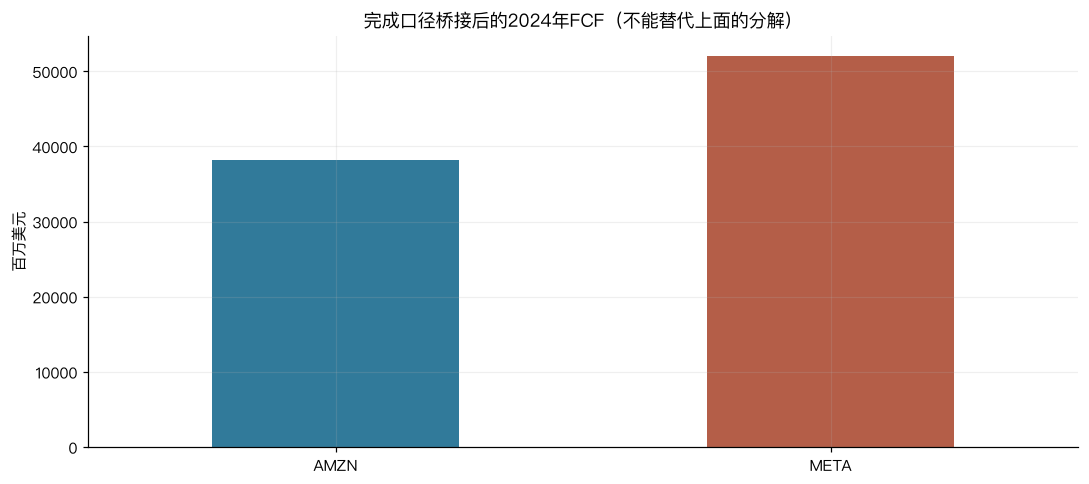

In [5]:
a=f[(f.symbol=="AMZN")&(f.fiscal_year==2024)].iloc[0]
m=f[(f.symbol=="META")&(f.fiscal_year==2024)].iloc[0]
amzn_fcf=a.cfo_usd_m-(a.cash_ppe_usd_m-a.ppe_proceeds_usd_m)
meta_fcf=m.cfo_usd_m-m.cash_ppe_usd_m-m.lease_principal_usd_m
assert amzn_fcf==38219 and meta_fcf==52103
bridge=pd.DataFrame({"AMZN":[a.cfo_usd_m,-a.cash_ppe_usd_m,a.ppe_proceeds_usd_m,0,amzn_fcf],"META":[m.cfo_usd_m,-m.cash_ppe_usd_m,0,-m.lease_principal_usd_m,meta_fcf]},index=["经营现金流","现金购置","出售及激励调整","租赁本金调整","公司披露FCF"])
display(bridge)
bridge.iloc[-1].plot.bar(title="完成口径桥接后的2024年FCF（不能替代上面的分解）",color=["#317a9a","#b45e48"])
plt.ylabel("百万美元"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

桥接表中的 0 是“本次公式不使用这项调整”，不是宣称公司没有该类现金流。其他公司的未录入字段仍保留空白。折旧列的范围也不同：Amazon 包含资本化内容和租赁资产等，Alphabet 是固定资产折旧；因此这里不画一个混合口径的“折旧排行榜”。

## 4. 季度现金流为什么不能直接拿累计值

10-Q 的现金流常为年初至今累计数。下面是**纯教学夹具，单位 USD，非公司实绩**：第一季度 10、半年累计 25、九个月累计 39、全年 60，对应单季度 10、15、14、21。真实转换还必须核对财政年起点、标签、单位和修订版本；不能把不同版本硬相减。

In [6]:
from tools.research_playbook.analysis import quarterly_cashflow
toy=pd.DataFrame({"symbol":["教学夹具"]*4,"fiscal_start":["2024-01-01"]*4,"quarter":[1,2,3,4],"value":[10,25,39,60],"available_at":["2024-05-01","2024-08-01","2024-11-01","2025-02-01"],"vintage":["已对齐修订口径"]*4,"unit":["USD"]*4,"metric":["cfo"]*4})
display(quarterly_cashflow(toy)[["quarter","value","quarter_value","quarter_available_at"]])

,quarter,value,quarter_value,quarter_available_at
0,1,10,10.0,2024-05-01 00:00:00+00:00
1,2,25,15.0,2024-08-01 00:00:00+00:00
2,3,39,14.0,2024-11-01 00:00:00+00:00
3,4,60,21.0,2025-02-01 00:00:00+00:00


## 5. 下一份财报应该补什么

继续使用这张表的主键，增加实际公告时刻、季度收入、单季经营现金流、现金与含租赁资本开支、债务到期、折旧寿命变化、管理层指引及页码。若要回答 AI 变现，还需要云业务分部与 AI 专属收入／订单证据；总公司收入增长不能替代它。

**反证条件：** 资本开支上升但分部收入、利用率和现金回收长期没有改善，或改善来自延长折旧寿命而非现金创造，应降低对原假设的信心。本年度样本不足以作因果判断。

来源链接可点击上面的 `url`；手工录入表和字段约定在 `research/data/`。SEC 自动季度接口仍待真实身份配置与实际验收。